In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import glob

In [2]:
# path = "rate_plots/group1 + 2,4-difluorobenzoyl chloride times_and_concs.xlsx"

In [3]:
# Extract the first two columns from the dataframe
processed_df = pd.DataFrame(columns=["amine", "acid_chloride", "times", "one_over_a", "slope", "path"])
error_df = pd.DataFrame(columns=["amine", "acid_chloride", "times", "one_over_a", "path"])

for path in glob.glob("rate_plots/*.xlsx"):
    try:
        # Specify the engine explicitly and verify file integrity
        file_df = pd.read_excel(path, engine="openpyxl").drop(columns=['Unnamed: 0'])
        
        for col_idx in range(0, file_df.shape[1], 2):
            first_two_columns = file_df.iloc[:, col_idx:col_idx+2].dropna()
            times = first_two_columns.iloc[:, 0]
            one_over_a = first_two_columns.iloc[:, 1]

            # Get the column names for the current pair of columns
            time_col_name = file_df.columns[col_idx]
            amine = time_col_name.split("+")[0]
            if amine == "blank":
                amine = "Controls"
            acid_chloride = time_col_name.split("+")[1].replace(" times", "")

            try:
                slope = np.polyfit(times, one_over_a, 1)[0]
            except:
                print(f"Error fitting slope for {amine} + {acid_chloride} at {path}")
                print(times)
                print(one_over_a)

                row = {
                    "amine": amine,
                    "acid_chloride": acid_chloride,
                    "times": np.array(times),
                    "one_over_a": np.array(one_over_a),
                    "path": path,
                }
                error_df = pd.concat([error_df, pd.DataFrame([row])], ignore_index=True)

                continue

            row = {
                "amine": amine,
                "acid_chloride": acid_chloride,
                "times": np.array(times),
                "one_over_a": np.array(one_over_a),
                "slope": slope,
                "path": path,
            }
            processed_df = pd.concat([processed_df, pd.DataFrame([row])], ignore_index=True)
    except Exception as e:
        print(f"Error processing file {path}: {str(e)}")
        continue

/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/p

Error fitting slope for morpholine + valeroyl chloride at rate_plots/group2 + valeroyl chloride times_and_concs.xlsx
4    0.0
5    0.0
6    0.0
7    0.0
Name: morpholine+valeroyl chloride times, dtype: float64
4     2560.0
5     5120.0
6    10240.0
7    20480.0
Name: morpholine+valeroyl chloride 1/[A], dtype: float64
 ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value
Error fitting slope for 3 amino pentane + valeroyl chloride at rate_plots/group2 + valeroyl chloride times_and_concs.xlsx
4    0.0
5    0.0
6    0.0
7    0.0
Name: 3 amino pentane+valeroyl chloride times, dtype: float64
4     2560.0
5     5120.0
6    10240.0
7    20480.0
Name: 3 amino pentane+valeroyl chloride 1/[A], dtype: float64
 ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  5 had an illegal value
 ** On entry to DLASCL

/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3579: RankWarning: Polyfit may be poorly conditioned
  exec(code_obj, self.user_global_ns, self.user_ns)
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3579: RankWarning: Polyfit may be poorly conditioned
  exec(code_obj, self.user_global_ns, self.user_ns)
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid

Error fitting slope for 2-methylpiperidine + 2,4-difluorobenzoyl chloride at rate_plots/group2 + 2,4-difluorobenzoyl chloride times_and_concs.xlsx ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  5 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value

3    0.0
4    0.0
5    0.0
6    0.0
7    0.0
Name: 2-methylpiperidine+2,4-difluorobenzoyl chloride times, dtype: float64
3     1280.0
4     2560.0
5     5120.0
6    10240.0
7    20480.0
Name: 2-methylpiperidine+2,4-difluorobenzoyl chloride 1/[A], dtype: float64
Error fitting slope for morpholine + 2,4-difluorobenzoyl chloride at rate_plots/group2 + 2,4-difluorobenzoyl chloride times_and_concs.xlsx
3    0.0
4    0.0
5    0.0
6    0.0
7    0.0
Name: morpholine+

/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/p

...

/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/p

Error fitting slope for 4-tertbutylaniline + 2-phenylbutyryl chloride at rate_plots/group2 + 2-phenylbutyryl chloride times_and_concs.xlsx ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  5 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value

0    0
1    0
2    0
3    0
4    0
5    0
6    0
Name: 4-tertbutylaniline+2-phenylbutyryl chloride times, dtype: int64
0      160
1      320
2      640
3     1280
4     2560
5     5120
6    20480
Name: 4-tertbutylaniline+2-phenylbutyryl chloride 1/[A], dtype: int64
Error fitting slope for morpholine + 2-phenylbutyryl chloride at rate_plots/group2 + 2-phenylbutyryl chloride times_and_concs.xlsx
0    0
1    0
2    0
3    0
4    0
5    0
6    0
Name: morpholine+2-phenyl

/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/numpy/lib/polynomial.py:667: RuntimeWarning: invalid value encountered in divide
  lhs /= scale
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3579: RankWarning: Polyfit may be poorly conditioned
  exec(code_obj, self.user_global_ns, self.user_ns

Error fitting slope for tertbutylamine + 4-bromobenzoyl chloride at rate_plots/group1 + 4-bromobenzoyl chloride times_and_concs.xlsx ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value
 ** On entry to DLASCLS parameter number  5 had an illegal value
 ** On entry to DLASCLS parameter number  4 had an illegal value

0    0
1    0
2    0
3    0
4    0
5    0
6    0
7    0
Name: tertbutylamine+4-bromobenzoyl chloride times, dtype: int64
0      160
1      320
2      640
3     1280
4     2560
5     5120
6    10240
7    20480
Name: tertbutylamine+4-bromobenzoyl chloride 1/[A], dtype: int64


/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3579: RankWarning: Polyfit may be poorly conditioned
  exec(code_obj, self.user_global_ns, self.user_ns)
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3579: RankWarning: Polyfit may be poorly conditioned
  exec(code_obj, self.user_global_ns, self.user_ns)
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3579: RankWarning: Polyfit may be poorly conditioned
  exec(code_obj, self.user_global_ns, self.user_ns)
/Users/jose/miniconda3/envs/amides/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3579: RankWarning: Polyfit may be poorly conditioned
  exec(code_obj, self.user_global_ns, self.user_ns)


In [4]:
processed_df

,amine,acid_chloride,times,one_over_a,slope,path
0,tertbutylamine,"2,4-dichlorobenzoyl chloride","[12.0, 56.0, 309.0]","[1280.0, 2560.0, 5120.0]",11.965178,"rate_plots/group1 + 2,4-dichlorobenzoyl chlori..."
1,Controls,"2,4-dichlorobenzoyl chloride","[12.0, 44.0, 174.0]","[1280.0, 2560.0, 5120.0]",22.546640,"rate_plots/group1 + 2,4-dichlorobenzoyl chlori..."
2,4-fluoroaniline,"2,4-dichlorobenzoyl chloride","[5.0, 12.0, 56.0]","[1280.0, 2560.0, 5120.0]",69.219363,"rate_plots/group1 + 2,4-dichlorobenzoyl chlori..."
3,p-anisidine,"2,4-dichlorobenzoyl chloride","[0.0, 0.0, 3.0, 7.0]","[1280.0, 2560.0, 5120.0, 20480.0]",2579.393939,"rate_plots/group1 + 2,4-dichlorobenzoyl chlori..."
4,aniline,"2,4-dichlorobenzoyl chloride","[8.0, 12.0, 52.0]","[1280.0, 2560.0, 5120.0]",77.837838,"rate_plots/group1 + 2,4-dichlorobenzoyl chlori..."
...,...,...,...,...,...,...
1137,"2,6-diisopropylaniline",4-fluorobenzoyl chloride-3C,"[6.0, 31.0, 129.0, 333.0]","[640.0, 1280.0, 2560.0, 5120.0]",13.294557,rate_plots/group1 + 4-fluorobenzoyl chloride-3...
1138,dicyclohexylamine,4-fluorobenzoyl chloride-3C,"[2.0, 22.0, 99.0, 306.0]","[640.0, 1280.0, 2560.0, 5120.0]",14.158742,rate_plots/group1 + 4-fluorobenzoyl chloride-3...
1139,4-hexylaniline,4-fluorobenzoyl chloride-3C,"[2.0, 4.0, 18.0, 31.0, 58.0]","[320.0, 640.0, 1280.0, 2560.0, 5120.0]",84.326778,rate_plots/group1 + 4-fluorobenzoyl chloride-3...
1140,2-methylthioaniline,4-fluorobenzoyl chloride-3C,"[43.0, 174.0, 471.0, 429.0]","[1280.0, 2560.0, 5120.0, 10240.0]",15.413125,rate_plots/group1 + 4-fluorobenzoyl chloride-3...


In [5]:
error_df

,amine,acid_chloride,times,one_over_a,path
0,morpholine,valeroyl chloride,"[0.0, 0.0, 0.0, 0.0]","[2560.0, 5120.0, 10240.0, 20480.0]",rate_plots/group2 + valeroyl chloride times_an...
1,3 amino pentane,valeroyl chloride,"[0.0, 0.0, 0.0, 0.0]","[2560.0, 5120.0, 10240.0, 20480.0]",rate_plots/group2 + valeroyl chloride times_an...
2,2-methylpiperidine,4-chloro benzoyl chloride,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[160.0, 320.0, 640.0, 1280.0, 2560.0, 5120.0, ...",rate_plots/group2 + 4-chloro benzoyl chloride ...
3,morpholine,4-chloro benzoyl chloride,"[0, 0, 0, 0, 0, 0, 0, 0]","[160, 320, 640, 1280, 2560, 5120, 10240, 20480]",rate_plots/group2 + 4-chloro benzoyl chloride ...
4,3 amino pentane,4-chloro benzoyl chloride,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[160.0, 320.0, 640.0, 1280.0, 2560.0, 5120.0]",rate_plots/group2 + 4-chloro benzoyl chloride ...
5,2-methylpiperidine,isobutyryl chloride,"[0.0, 0.0, 0.0, 0.0]","[160.0, 320.0, 640.0, 1280.0]",rate_plots/group2 + isobutyryl chloride times_...
6,morpholine,isobutyryl chloride,"[0, 0, 0, 0, 0, 0, 0, 0]","[160, 320, 640, 1280, 2560, 5120, 10240, 20480]",rate_plots/group2 + isobutyryl chloride times_...
7,3 amino pentane,isobutyryl chloride,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[160.0, 320.0, 640.0, 1280.0, 2560.0, 5120.0]",rate_plots/group2 + isobutyryl chloride times_...
8,2-methylpiperidine,4-trifluoromethylbenzoyl chloride,"[0.0, 0.0, 0.0, 0.0, 0.0]","[1280.0, 2560.0, 5120.0, 10240.0, 20480.0]",rate_plots/group2 + 4-trifluoromethylbenzoyl c...
9,morpholine,4-trifluoromethylbenzoyl chloride,"[0.0, 0.0, 0.0, 0.0]","[1280.0, 2560.0, 5120.0, 10240.0]",rate_plots/group2 + 4-trifluoromethylbenzoyl c...


In [6]:
complete_df = pd.concat([processed_df[['amine', 'acid_chloride', 'times', 'one_over_a']], error_df[['amine', 'acid_chloride', 'times', 'one_over_a']]], ignore_index=True)
complete_df

,amine,acid_chloride,times,one_over_a
0,tertbutylamine,"2,4-dichlorobenzoyl chloride","[12.0, 56.0, 309.0]","[1280.0, 2560.0, 5120.0]"
1,Controls,"2,4-dichlorobenzoyl chloride","[12.0, 44.0, 174.0]","[1280.0, 2560.0, 5120.0]"
2,4-fluoroaniline,"2,4-dichlorobenzoyl chloride","[5.0, 12.0, 56.0]","[1280.0, 2560.0, 5120.0]"
3,p-anisidine,"2,4-dichlorobenzoyl chloride","[0.0, 0.0, 3.0, 7.0]","[1280.0, 2560.0, 5120.0, 20480.0]"
4,aniline,"2,4-dichlorobenzoyl chloride","[8.0, 12.0, 52.0]","[1280.0, 2560.0, 5120.0]"
...,...,...,...,...
1183,2-methylpiperidine,dodecanoyl chloride,"[0.0, 0.0, 0.0]","[2560.0, 5120.0, 20480.0]"
1184,2-methylpiperidine,4-trifluoromethoxybenzoyl chloride,"[0.0, 0.0, 0.0, 0.0]","[320.0, 640.0, 1280.0, 2560.0]"
1185,morpholine,4-trifluoromethoxybenzoyl chloride,"[0, 0, 0, 0, 0, 0, 0, 0]","[160, 320, 640, 1280, 2560, 5120, 10240, 20480]"
1186,3 amino pentane,4-trifluoromethoxybenzoyl chloride,"[0.0, 0.0, 0.0, 0.0, 0.0]","[320.0, 640.0, 1280.0, 2560.0, 5120.0]"


In [7]:
complete_df.to_pickle('data/complete_rate_plots.pkl')

In [8]:
# Check for duplicate amine-acid_chloride pairs
duplicate_pairs = processed_df.groupby(['amine', 'acid_chloride']).size().reset_index(name='count')
duplicates = duplicate_pairs[duplicate_pairs['count'] > 1]

if len(duplicates) > 0:
    print(f"Found {len(duplicates)} duplicate amine-acid_chloride pairs:")
    print(duplicates)
    
    # Show the slopes for each duplicate pair
    for _, row in duplicates.iterrows():
        amine = row['amine']
        acid = row['acid_chloride']
        dups = processed_df[(processed_df['amine'] == amine) & (processed_df['acid_chloride'] == acid)]
        print(f"\nSlopes for {amine} + {acid}:")
        for _, dup_row in dups.iterrows():
            print(f"  Path: {dup_row['path']}, Slope: {dup_row['slope']:.6f}")

In [9]:
# Access the row where amine is "2,4,6-trimethylaniline" and acid_chloride is "4-fluorobenzoyl"
temp = processed_df[(processed_df['amine'] == '2,4,6-trimethylaniline') & 
             (processed_df['acid_chloride'] == '4-fluorobenzoyl')]
temp

,amine,acid_chloride,times,one_over_a,slope,path


In [10]:
zips = []
for i, idx in enumerate(temp.index):
    zip_item = list(zip(temp['times'][idx], temp['one_over_a'][idx]))
    zips.append(zip_item)
zips

[]

In [11]:
d = {}
for zip_item in zips:
    for time, one_over_a in zip_item:
        if one_over_a not in d:
            d[one_over_a] = []
        d[one_over_a].append(time)

d

{}

TypeError: expected non-empty vector for x

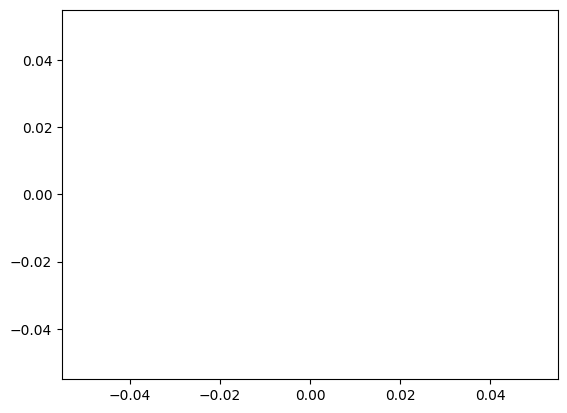

In [12]:
x = np.array([np.mean(d[key]) for key in d.keys()])
y = np.array(list(d.keys()))
plt.scatter(x, y)
slope, intercept = np.polyfit(x, y, 1)
plt.plot(x, slope*x + intercept, color='black')
plt.xlabel('1/[A] (M⁻¹)')
plt.ylabel('Time (min)')
plt.title('Kinetic Plot for 2,4,6-trimethylaniline + 4-fluorobenzoyl')
# Display equation on the plot
equation = f'y = {slope:.2f}x + {intercept:.2f}'
plt.text(0.05, 0.95, equation, transform=plt.gca().transAxes, 
         bbox=dict(facecolor='white', alpha=0.8))
plt.grid(True)
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
complete_df[complete_df['amine'] == 'm-toluidine']

,amine,acid_chloride,times,one_over_a
89,m-toluidine,heptanoyl chloride,"[6.0, 8.0, 35.0]","[5120.0, 10240.0, 20480.0]"
110,m-toluidine,4-ethylbenzoyl chloride,"[18.0, 35.0, 72.0, 126.0]","[320.0, 640.0, 1280.0, 2560.0]"
216,m-toluidine,"2,4-difluorobenzoyl chloride","[6.0, 14.0, 40.0]","[2560.0, 10240.0, 20480.0]"
228,m-toluidine,4-phenylbenzoyl chloride,"[0.0, 8.0, 21.0, 57.0, 123.0, 195.0, 411.0]","[160.0, 320.0, 640.0, 1280.0, 2560.0, 5120.0, ..."
240,m-toluidine,4-trifluoromethylbenzoyl chloride,"[6.0, 11.0, 30.0, 55.0]","[1280.0, 2560.0, 10240.0, 20480.0]"
286,m-toluidine,4-(trifluoromethylthio)benzoyl chloride,"[10.0, 35.0, 120.0, 255.0]","[2560.0, 5120.0, 10240.0, 20480.0]"
298,m-toluidine,2-naphthoyl chloride,"[6.0, 18.0, 56.0, 87.0]","[320.0, 640.0, 1280.0, 2560.0]"
320,m-toluidine,2-ethylhexanoyl chloride,"[0.0, 12.0, 26.0, 66.0]","[160.0, 320.0, 640.0, 1280.0]"
332,m-toluidine,4-fluorobenzoyl chloride-3C,"[7.0, 4.0, 10.0, 35.0, 78.0, 126.0, 261.0]","[160.0, 320.0, 640.0, 1280.0, 2560.0, 5120.0, ..."
344,m-toluidine,isobutyryl chloride,"[3.0, 13.0, 23.0, 55.0]","[2560.0, 5120.0, 10240.0, 20480.0]"
